In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/selva86/datasets/master/supermarket_sales.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [ ]:

print("Column Names:")
print(df.columns.tolist())


Column Names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']


In [ ]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [ ]:

display(df.describe(include="all"))


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
count,1000,1000,1000,1000,1000,1000,1000.000000,1000.000000,1000.000000,1000.000000,1000,1000,1000,1000.00000,1.000000e+03,1000.000000,1000.00000
unique,1000,3,3,2,2,6,NaN,NaN,NaN,NaN,89,506,3,NaN,NaN,NaN,NaN
top,849-09-3807,A,Yangon,Member,Female,Fashion accessories,NaN,NaN,NaN,NaN,2/7/2019,19:48,Ewallet,NaN,NaN,NaN,NaN
freq,1,340,340,501,501,178,NaN,NaN,NaN,NaN,20,7,345,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,55.672130,5.510000,15.379369,322.966749,NaN,NaN,NaN,307.58738,4.761905e+00,15.379369,6.97270
std,NaN,NaN,NaN,NaN,NaN,NaN,26.494628,2.923431,11.708825,245.885335,NaN,NaN,NaN,234.17651,6.131498e-14,11.708825,1.71858
min,NaN,NaN,NaN,NaN,NaN,NaN,10.080000,1.000000,0.508500,10.678500,NaN,NaN,NaN,10.17000,4.761905e+00,0.508500,4.00000
25%,NaN,NaN,NaN,NaN,NaN,NaN,32.875000,3.000000,5.924875,124.422375,NaN,NaN,NaN,118.49750,4.761905e+00,5.924875,5.50000
50%,NaN,NaN,NaN,NaN,NaN,NaN,55.230000,5.000000,12.088000,253.848000,NaN,NaN,NaN,241.76000,4.761905e+00,12.088000,7.00000
75%,NaN,NaN,NaN,NaN,NaN,NaN,77.935000,8.000000,22.445250,471.350250,NaN,NaN,NaN,448.90500,4.761905e+00,22.445250,8.50000


In [ ]:

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [ ]:

print("Total duplicate rows:", df.duplicated().sum())


Total duplicate rows: 0


In [ ]:

print("Rows before cleaning:", len(df))

df = df.drop_duplicates().copy()

# Fill missing numerical values with the median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the most frequent value
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Rows after cleaning:", len(df))
print("Remaining missing values:", df.isnull().sum().sum())


Rows before cleaning: 1000
Rows after cleaning: 1000
Remaining missing values: 0


In [ ]:

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["Month"] = df["Date"].dt.month_name()
df["Day"] = df["Date"].dt.day_name()

print(df[["Date", "Month", "Day"]].head())


        Date     Month       Day
0 2019-01-05   January  Saturday
1 2019-03-08     March    Friday
2 2019-03-03     March    Sunday
3 2019-01-27   January    Sunday
4 2019-02-08  February    Friday


In [ ]:

total_revenue = df["Total"].sum()
average_transaction = df["Total"].mean()
total_transactions = len(df)
total_quantity_sold = df["Quantity"].sum()
average_rating = df["Rating"].mean()

print("===== SALES PERFORMANCE REPORT =====")
print(f"Total Revenue: {total_revenue:.2f}")
print(f"Average Transaction Value: {average_transaction:.2f}")
print(f"Total Transactions: {total_transactions}")
print(f"Total Quantity Sold: {total_quantity_sold}")
print(f"Average Customer Rating: {average_rating:.2f}")


===== SALES PERFORMANCE REPORT =====
Total Revenue: 322966.75
Average Transaction Value: 322.97
Total Transactions: 1000
Total Quantity Sold: 5510
Average Customer Rating: 6.97


In [ ]:

category_sales = (
    df.groupby("Product line")["Total"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Product Line:")
display(category_sales)


Revenue by Product Line:


,Total
Product line,
Food and beverages,56144.8440
Sports and travel,55122.8265
Electronic accessories,54337.5315
Fashion accessories,54305.8950
Home and lifestyle,53861.9130
Health and beauty,49193.7390


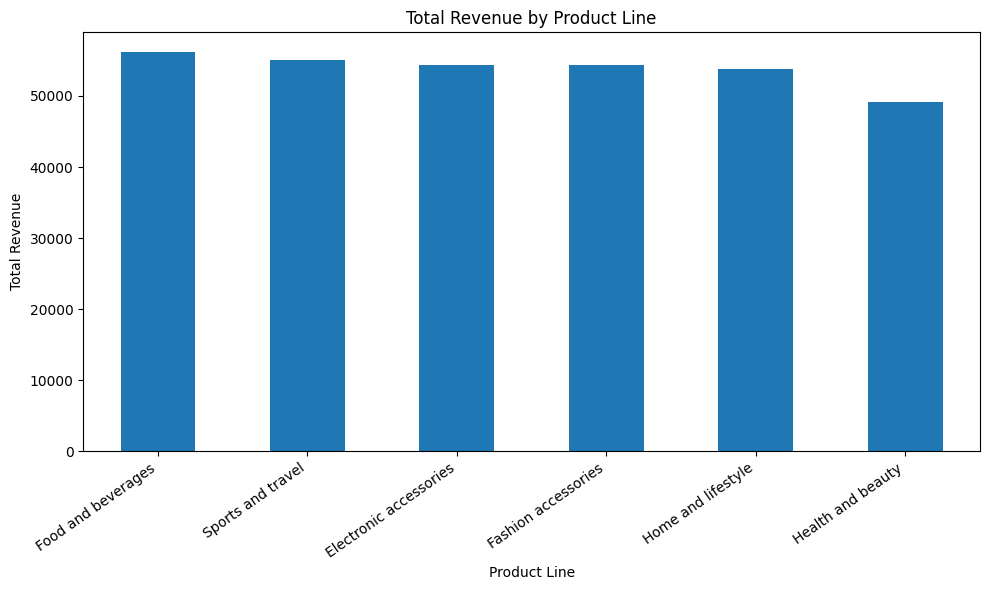

In [ ]:

plt.figure(figsize=(10, 6))

category_sales.plot(kind="bar")

plt.title("Total Revenue by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Revenue")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

branch_sales = (
    df.groupby("Branch")["Total"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Branch:")
display(branch_sales)


Revenue by Branch:


,Total
Branch,
C,110568.7065
A,106200.3705
B,106197.6720


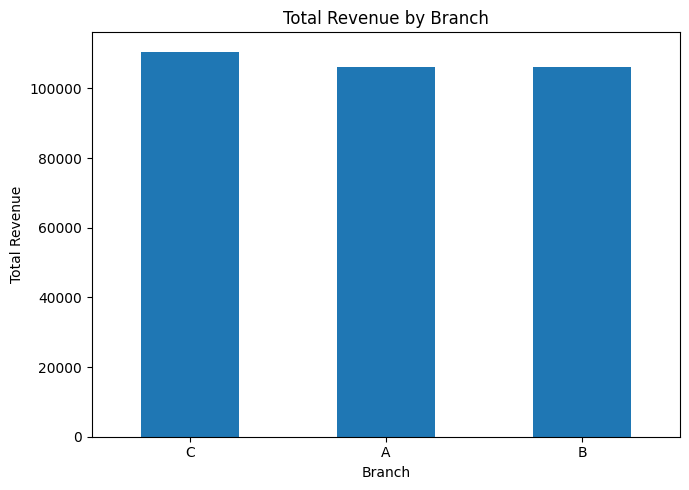

In [ ]:

plt.figure(figsize=(7, 5))

branch_sales.plot(kind="bar")

plt.title("Total Revenue by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

payment_counts = df["Payment"].value_counts()

print("Transactions by Payment Method:")
display(payment_counts)

print("\nRevenue by Payment Method:")
display(df.groupby("Payment")["Total"].sum().sort_values(ascending=False))


Transactions by Payment Method:


,count
Payment,
Ewallet,345
Cash,344
Credit card,311



Revenue by Payment Method:


,Total
Payment,
Cash,112206.570
Ewallet,109993.107
Credit card,100767.072


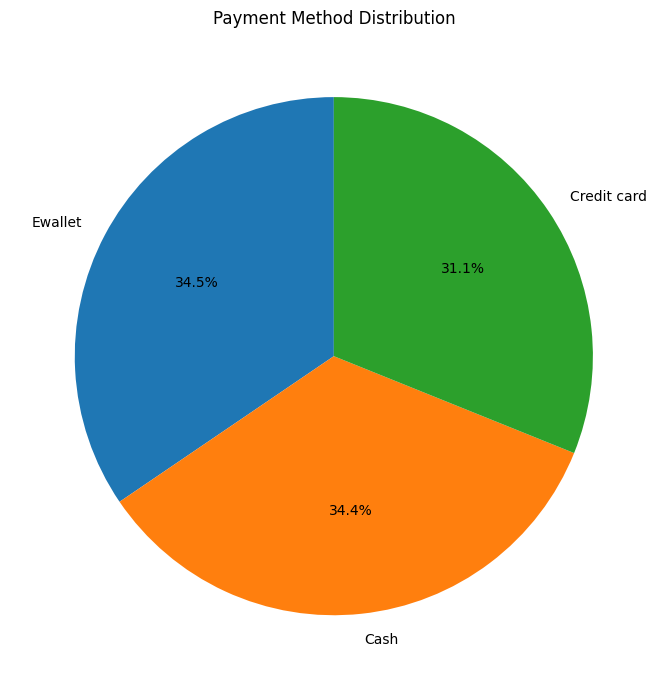

In [ ]:

plt.figure(figsize=(7, 7))

payment_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Method Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [ ]:

daily_sales = (
    df.dropna(subset=["Date"])
    .groupby("Date")["Total"]
    .sum()
    .sort_index()
)

display(daily_sales.head())


,Total
Date,
2019-01-01,4745.1810
2019-01-02,1945.5030
2019-01-03,2078.1285
2019-01-04,1623.6885
2019-01-05,3536.6835


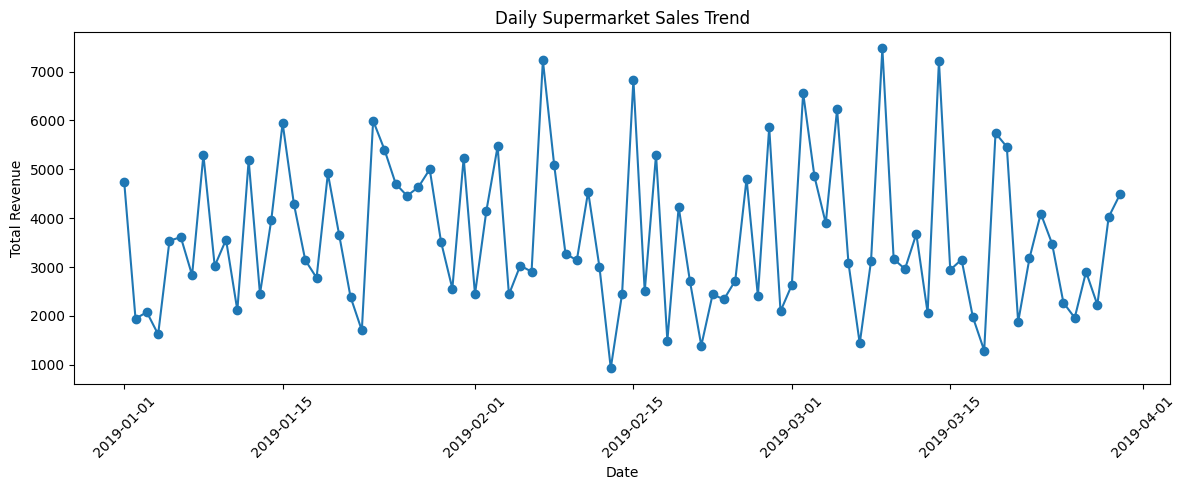

In [ ]:

plt.figure(figsize=(12, 5))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    marker="o"
)

plt.title("Daily Supermarket Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


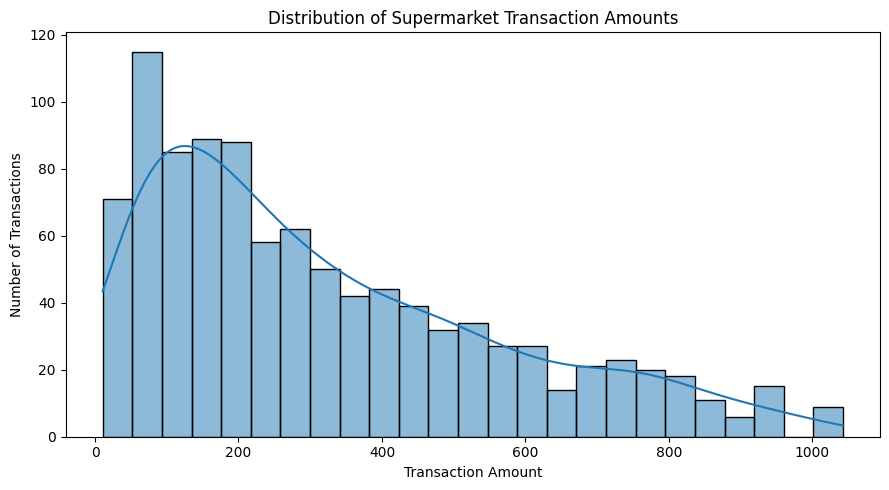

In [ ]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Total",
    bins=25,
    kde=True
)

plt.title("Distribution of Supermarket Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


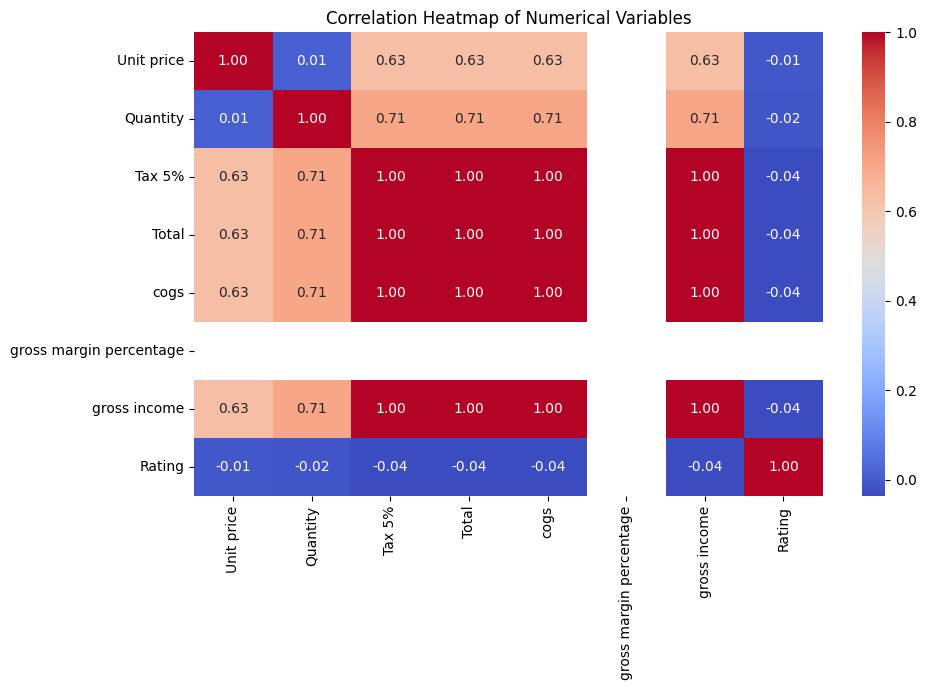

In [ ]:

numeric_data = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


In [ ]:

category_sales = df.groupby("Product line")["Total"].sum()
branch_sales = df.groupby("Branch")["Total"].sum()
payment_counts = df["Payment"].value_counts()

best_category = category_sales.idxmax()
best_branch = branch_sales.idxmax()
popular_payment = payment_counts.idxmax()

highest_sales_date = daily_sales.idxmax()
highest_daily_revenue = daily_sales.max()

print("===== KEY BUSINESS FINDINGS =====")
print("Highest revenue product line:", best_category)
print("Highest revenue branch:", best_branch)
print("Most frequently used payment method:", popular_payment)
print("Highest revenue date:", highest_sales_date.date())
print(f"Highest daily revenue: {highest_daily_revenue:.2f}")


===== KEY BUSINESS FINDINGS =====
Highest revenue product line: Food and beverages
Highest revenue branch: C
Most frequently used payment method: Ewallet
Highest revenue date: 2019-03-09
Highest daily revenue: 7474.05


In [ ]:

print("===== PROJECT SUMMARY =====")
print(f"Total revenue: {df['Total'].sum():.2f}")
print(f"Average transaction value: {df['Total'].mean():.2f}")
print(f"Total transactions analyzed: {len(df)}")
print(f"Total quantity sold: {df['Quantity'].sum()}")

print("\nMain findings:")
print(f"Top product line by revenue: {best_category}")
print(f"Top branch by revenue: {best_branch}")
print(f"Most frequently used payment: {popular_payment}")

print("\nRecommendations:")
print("1. Use product-level revenue to guide inventory planning.")
print("2. Compare branch performance to identify improvement opportunities.")
print("3. Use payment preferences to improve checkout convenience.")
print("4. Monitor daily revenue to understand sales fluctuations.")


===== PROJECT SUMMARY =====
Total revenue: 322966.75
Average transaction value: 322.97
Total transactions analyzed: 1000
Total quantity sold: 5510

Main findings:
Top product line by revenue: Food and beverages
Top branch by revenue: C
Most frequently used payment: Ewallet

Recommendations:
1. Use product-level revenue to guide inventory planning.
2. Compare branch performance to identify improvement opportunities.
3. Use payment preferences to improve checkout convenience.
4. Monitor daily revenue to understand sales fluctuations.


In [ ]:

df.to_csv("cleaned_supermarket_sales.csv", index=False)

print("CSV file created successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))


In [ ]:

df.to_csv("/content/cleaned_supermarket_sales.csv", index=False)

print("Cleaned dataset exported successfully!")


Cleaned dataset exported successfully!
